#### Objective
- pipelinify & optimize AlosPolarimetric to enable parameter search testing for statistical/empirical identification of algorithmic stability
- replace the clumsy manual Adam optimizer with a torch-based workflow


In [4]:
import os, importlib, netCDF4
import numpy as np
import scipy
import matplotlib.pyplot as plt

import torch.nn as nn
import torch

import Model
import PyPreprocess

#MAKE SURE CUDA IS WORKING RIGHT!
print(torch.version.cuda)
print(torch.cuda.is_available())
a = torch.rand(1).cuda()
print(a)

INFO: org.esa.snap.core.gpf.operators.tooladapter.ToolAdapterIO: Initializing external tool adapters
SLF4J: Class path contains multiple SLF4J bindings.
SLF4J: Found binding in [jar:file:/home/adminix/esa-snap/snap/modules/ext/org.esa.snap.snap-netcdf/org-slf4j/slf4j-simple.jar!/org/slf4j/impl/StaticLoggerBinder.class]
SLF4J: Found binding in [jar:file:/home/adminix/esa-snap/snap/modules/org.esa.snap.snap-netcdf/org-slf4j/slf4j-simple.jar!/org/slf4j/impl/StaticLoggerBinder.class]
SLF4J: See http://www.slf4j.org/codes.html#multiple_bindings for an explanation.
SLF4J: Actual binding is of type [org.slf4j.impl.SimpleLoggerFactory]
INFO: org.esa.snap.core.util.EngineVersionCheckActivator: Please check regularly for new updates for the best SNAP experience.
Currently installed 12.0.0, available is 13.0.0.
Please visit http://step.esa.int



13.0
True
tensor([0.8070], device='cuda:0')


In [5]:
import importlib
importlib.reload(PyPreprocess)

<module 'PyPreprocess' from '/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/torched/PyPreprocess.py'>

In [152]:
# -- RVILab SPACE SETUP -- #

load_new = False
#fn_1 = "/mnt/c/slc_cache/251114rGreenland/ALPSRP060811420-L1.1.zip"
#fn_2 = "/mnt/c/slc_cache/251114rGreenland/ALPSRP067521420-L1.1.zip"
cache_dir = 'SNAPNative_GreenlandPair'

if (load_new):
    dataset = PyPreprocess.Pair_Dataset_SNAPNative(cache_dir=cache_dir, read_nc=True)
    dataset.cache(fn_cache)
else:
    dataset = PyPreprocess.Pair_Dataset_SNAPh5.load_cache(cache_dir)

fn_it = "cmems_mod_arc_phy_my_nextsim_P1M-m_1760090640041.nc"
data_it = netCDF4.Dataset(fn_it, 'r')
it_ll = np.array(np.meshgrid(data_it.variables['latitude'], data_it.variables['longitude'], indexing='ij'))
#sit_interpolated = data_it.variables['sithick'][0]
print(f"imported {fn_it}")

it_mesh = np.array(np.meshgrid(np.arange(it_ll[0].shape[0]), np.arange(it_ll[0].shape[1]), indexing='ij'))
tmp = (scipy.interpolate.RegularGridInterpolator((it_ll[0].mean(axis=1), it_ll[1].mean(axis=0)), it_mesh[0]),
       scipy.interpolate.RegularGridInterpolator((it_ll[0].mean(axis=1), it_ll[1].mean(axis=0)), it_mesh[1]))
#s1 pixel -> s1 lat/lon -> it pixel
tmp = (tmp[0](np.stack((dataset.lat.ravel(), dataset.lon.ravel()),axis=1)).reshape(dataset.lat.shape),
       tmp[1](np.stack((dataset.lat.ravel(), dataset.lon.ravel()),axis=1)).reshape(dataset.lat.shape))
it_coordmap = tmp
print("finished generating coordinate map.")

# interpolation of parameter
def processAux(auxdata, interpolate_empty=False):
    if (interpolate_empty):
        print("interpolation of null values specified - interpolating values..")
        tmp2 = it_mesh[:,~np.isnan(auxdata)]; tmp2 = np.stack(tmp2.reshape((2, tmp2.size//2)),axis=-1)
        auxdata = scipy.interpolate.LinearNDInterpolator(tmp2, auxdata[~np.isnan(auxdata)].ravel())
        auxdata = auxdata(np.stack(it_mesh.reshape((2,it_mesh.size//2)),axis=-1)).reshape(it_ll[0].shape)
        auxdata[np.isnan(auxdata)] = 0
        print("completed value generation.")
    else:
        auxdata[np.isnan(auxdata)] = 0
    return scipy.ndimage.map_coordinates(auxdata, it_coordmap)

sit = processAux(data_it.variables['sithick'][0])
sic = processAux(data_it.variables['siconc'][0])
sia = processAux(data_it.variables['siage'][0])
sivx = processAux(data_it.variables['vxsi'][0])
sivy = processAux(data_it.variables['vysi'][0])

sigs = dataset.s1.copy(), dataset.s2.copy()
sigs = [np.array([el for el in img] + [img[0]-img[3], img[1]+img[2]]) for img in sigs] #just a few more bands :3
cohs = PyPreprocess.stackcoh(sigs[0], sigs[1], window_size=4)

located cache at SNAPNative_GreenlandPair
extracting parameters..
retrieved metadata.
calculated vertical wavenumber.
retrieved SLC complex.
rescaling auxiliary data..
dataset loaded.
imported cmems_mod_arc_phy_my_nextsim_P1M-m_1760090640041.nc


ValueError: One of the requested xi is out of bounds in dimension 1

In [154]:
dataset.cache()

In [130]:
# (OPTIONAL) Coherence Complex Plane .gif maker

if not os.path.exists('framez_complekz'):
    os.makedirs('framez_complekz')

import matplotlib.cm as cm
cmap = cm.get_cmap('viridis')
color = np.array([1,2,3,4,5,6])*45
color = [cmap(el) for el in color]
lbpols = ['HH','HV','VH','VV','HH-VV','HV+VH']
k = 0
for itb in np.linspace(0,2,20):
    itb = 0.25
    mask = ((itb < sit)*(itb + 0.01 > sit))[5:-5,5:-5]
    tmp = cohs[:,5:-5,5:-5][:, mask]
    numsamps = min(30, tmp.shape[-1])
    tmp = tmp[:, np.unique(np.random.choice(np.arange(tmp.shape[-1]), numsamps))]
    for i in range(tmp.shape[-1]):
        k += 1
        plt.ylim(-1,1); plt.xlim(-1,1)
        plt.axhline(0, color='gray', linestyle='dotted'); plt.axvline(0, color='gray', linestyle='dotted')
        pf = np.polynomial.polynomial.polyfit(tmp[:,i].real, tmp[:,i].imag, deg=1)
        plt.plot(np.array((-1, 1)), pf[0]+pf[1]*np.array((-1,1)), linestyle='dashed')
        #for simplex in hull.simplices: plt.plot(tmp[simplex, i].real, tmp[simplex, i].imag, linestyle='dotted')
        handles = [plt.scatter(tmp[j,i].real, tmp[j,i].imag, color=color[j], label=lbpols[j]) for j in range(6)]
        plt.legend(handles, lbpols)
        plt.title(f"thickness={round(itb,3)}m")
        plt.savefig(f"framez_complekz/frame_{k}.png")
        #plt.show()
        plt.close()
    break

import imageio.v2
images = []
for i in range(k):
    filename = f'framez_complekz/frame_{i+1}.png'
    images.append(imageio.v2.imread(filename))
images += [images[i] for i in range(len(images)-1, -1, -1)]
imageio.v2.mimsave('animation.gif', images, fps=0.8, loop=0)

/tmp/ipykernel_927/2919055321.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')


In [133]:
import ModelRepresentationFNO as ModelF
myModule = ModelF.SeasonalRepresentation(64)


In [429]:
importlib.reload(Model)
import ModelRepresentationFNO as ModelF
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.empty_cache()
model2 = ModelF.TorchRVI2(cohs[:,5:-5,5:-5], dataset.ia1[5:-5,5:-5], dataset.k_z[5:-5,5:-5], wavelength=0.236,
                         vxt_layers=3, depth_bins=64).to(device)
optimizer = torch.optim.AdamW(model2.parameters(), lr=1e-2, weight_decay=1e-5)#.to(device)
loss_hist = []

In [409]:
#tmp = torch.empty(2,2).log_normal_(1,1); tmp
#model2.age

[000/1000] Loss: 1.788200e-01
[100/1000] Loss: 3.014125e-02
[200/1000] Loss: 2.900619e-02
[300/1000] Loss: 2.692471e-02
[400/1000] Loss: 2.440656e-02
[500/1000] Loss: 2.255122e-02
[600/1000] Loss: 2.139232e-02
[700/1000] Loss: 2.063983e-02
[800/1000] Loss: 1.998350e-02
[900/1000] Loss: 1.942485e-02


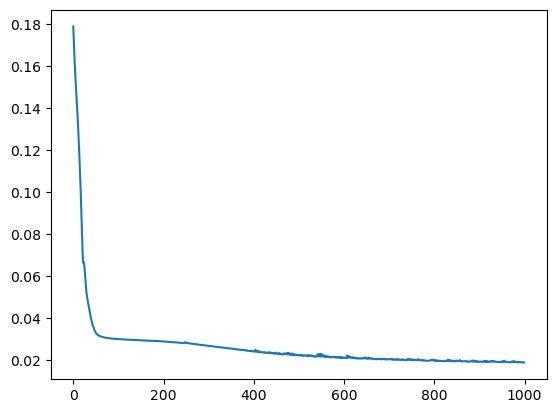

In [430]:
steps = 1000
for t in range(steps):
    optimizer.zero_grad()
    modelled = model2.forward()
    captured = model2.data_captured()
    loss = model2.loss_fn(modelled, captured)
    loss.backward()
    optimizer.step()
    #model2.steps += 1
    #scheduler.step()
    #sched_vxt.step()

    # Optional: parameter correction / clamping
    with torch.no_grad():
        model2.sv_ratio.clamp_(0.0, 999.0)
        model2.thickness.clamp_(0.0, 10.0) #0 to 10 metres
        model2.age.clamp_(0.0, 10.0) #0 to 10 years

    if t % 100 == 0:
        print(f"[{t:03d}/{steps}] Loss: {loss.item():.6e}")
    loss_hist.append(loss.item())
plt.plot(loss_hist)

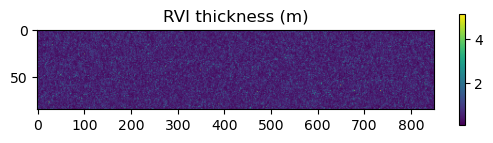

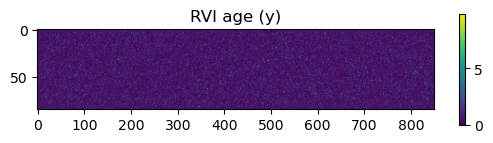

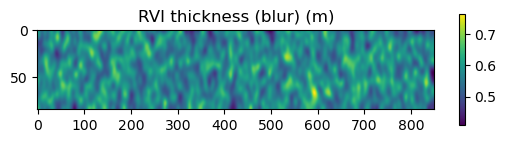

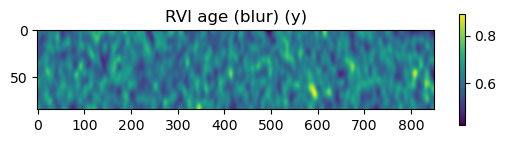

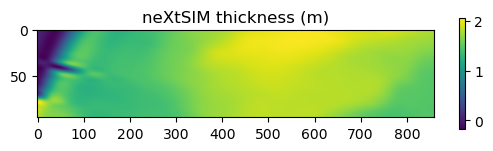

In [441]:
#[(name, torch.isnan(p).any()) for p in model2.parameters()]
def cp_read(x):
    return x.cpu().detach().numpy().T
tmp_div = (1+cp_read(model2.sv_ratio.sum(0))**2)
tmp = cp_read(model2.thickness) / tmp_div
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI thickness (m)"); plt.show()
tmp1 = cp_read(model2.age) / tmp_div
plt.imshow(tmp1, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI age (y)"); plt.show()

tmp = scipy.ndimage.gaussian_filter(tmp, sigma=4, radius=(20,150))
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI thickness (blur) (m)"); plt.show()
tmp = scipy.ndimage.gaussian_filter(tmp1, sigma=4, radius=(20,150))
plt.imshow(tmp, aspect=2); plt.colorbar(shrink=0.3); plt.title("RVI age (blur) (y)"); plt.show()

plt.imshow(sit.T, aspect=2); plt.colorbar(shrink=0.3); plt.title("neXtSIM thickness (m)"); plt.show()

In [135]:
if not os.path.exists('framez'):
    os.makedirs('framez')

depth_bins = 64

tmp_a = torch.zeros(1, 2)
k = 0
tmp_dbins = np.linspace(0,2,20)
tmp_abins = np.linspace(0,2,5)

#viewModel = model2.vxt.vxt_fnn
viewModel = ModelF.SeasonalRepresentation(depth_bins).to('cuda')

for i in tmp_dbins:
    tmp_a[0,0] = i
    k += 1
    tmp = []
    for j in tmp_abins:
        tmp_a[0,1] = j
        tmp = viewModel.forward(tmp_a.to('cuda')).cpu().detach().numpy()
        plt.plot(np.linspace(0,i,depth_bins), tmp.T)
    plt.title(f"thickness={round(i,3)}m")
    plt.xlabel("depth (m)"); plt.ylabel("ext (?)")
    plt.legend([f"age {el} y" for el in tmp_abins])
    plt.savefig(f"framez/frame_{k}.png")
    plt.close()
    
import imageio.v2
images = []
for i in range(k):
    filename = f'framez/frame_{i+1}.png'
    images.append(imageio.v2.imread(filename))
images += [images[i] for i in range(len(images)-1, -1, -1)]
imageio.v2.mimsave('animation.gif', images, fps=10, loop=0)